In [33]:
import numpy as np
import pandas as pd
import seaborn as sns
import math
import matplotlib.pyplot as plt

In [34]:
from pathlib import Path
path = Path.cwd().parents[1]/ "data" / "real_data"



In [35]:
COLUMNS = ["time"] + [f"A{i}" for i in range(2, 10)]
CLASS_NAMES = {1: "Rad Flow", 2: "Fpv Close", 3: "Fpv Open", 4: "High", 5: "Bypass", 6: "Bpv Close", 7: "Bpv Open"}
N_TRAIN = 43_500  # shuttle.parquet = shuttle.trn (pierwsze 43 500 wierszy) + shuttle.tst


def load_shuttle(path: Path, drop_time: bool = True) -> pd.DataFrame:
    df = pd.read_parquet(Path(path) / "multiclass" / "shuttle.parquet")
    df = df.rename(columns={f"f{i}": c for i, c in enumerate(COLUMNS)} | {"target": "class"})
    df.insert(0, "split", pd.Categorical(["train"] * N_TRAIN + ["test"] * (len(df) - N_TRAIN), categories=["train", "test"]))
    df["class"] = pd.Categorical(df["class"].map(CLASS_NAMES), categories=list(CLASS_NAMES.values()))

    if drop_time:
        df = df.drop(columns="time")
    return df

In [36]:
df = load_shuttle(path, drop_time=True)
feature_cols = [c for c in df.columns if c not in ("class", "split")]

In [44]:
df.head()

,split,A2,A3,A4,A5,A6,A7,A8,A9,class
0,train,21,77,0,28,0,27,48,22,Fpv Close
1,train,0,92,0,0,26,36,92,56,High
2,train,0,82,0,52,-5,29,30,2,Rad Flow
3,train,0,76,0,28,18,40,48,8,Rad Flow
4,train,0,79,0,34,-26,43,46,2,Rad Flow


In [38]:
print(df.shape)
print(pd.concat({"count": df["class"].value_counts(sort=False), "share": df["class"].value_counts(sort=False, normalize=True).round(4)}, axis=1))
print(df[feature_cols].describe().T)

(58000, 10)
           count   share
class                   
Rad Flow   45586  0.7860
Fpv Close     50  0.0009
Fpv Open     171  0.0029
High        8903  0.1535
Bypass      3267  0.0563
Bpv Close     10  0.0002
Bpv Open      13  0.0002
      count       mean         std      min   25%   50%   75%      max
A2  58000.0  -0.019448   77.958035  -4821.0   0.0   0.0   0.0   5075.0
A3  58000.0  85.349121    8.902769     21.0  79.0  83.0  89.0    149.0
A4  58000.0   0.259672   36.521516  -3939.0   0.0   0.0   0.0   3830.0
A5  58000.0  34.549862   21.660139   -188.0  26.0  42.0  46.0    436.0
A6  58000.0   1.608190  217.597675 -26739.0  -5.0   0.0   5.0  15164.0
A7  58000.0  37.092310   13.111428    -48.0  32.0  39.0  42.0    105.0
A8  58000.0  50.884552   21.418051   -353.0  37.0  44.0  60.0    270.0
A9  58000.0  13.932414   25.614018   -356.0   0.0   2.0  14.0    266.0


In [39]:
df[feature_cols].corr().style.background_gradient(cmap="coolwarm")

,A2,A3,A4,A5,A6,A7,A8,A9
A2,1.000000,-0.003156,-0.000054,-0.000308,-0.001119,-0.067371,-0.000952,0.033604
A3,-0.003156,1.000000,0.038119,0.255777,0.001338,0.429677,0.155236,-0.091114
A4,-0.000054,0.038119,1.000000,0.005932,0.063958,0.033189,0.009898,-0.008489
A5,-0.000308,0.255777,0.005932,1.000000,0.088553,0.223066,-0.914731,-0.875235
A6,-0.001119,0.001338,0.063958,0.088553,1.000000,0.001956,-0.089152,-0.075053
A7,-0.067371,0.429677,0.033189,0.223066,0.001956,1.000000,-0.054711,-0.556353
A8,-0.000952,0.155236,0.009898,-0.914731,-0.089152,-0.054711,1.000000,0.859692
A9,0.033604,-0.091114,-0.008489,-0.875235,-0.075053,-0.556353,0.859692,1.000000


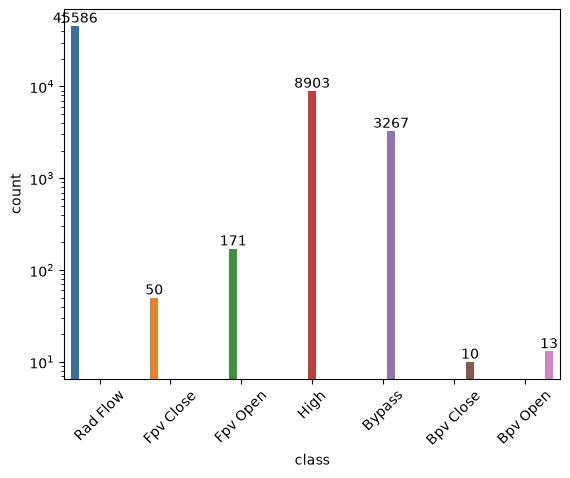

In [40]:
ax = sns.countplot(df, x="class", hue="class", legend=False)
for c in ax.containers:
    ax.bar_label(c)
ax.set_yscale("log")
ax.tick_params(axis="x", rotation=45)
plt.show()

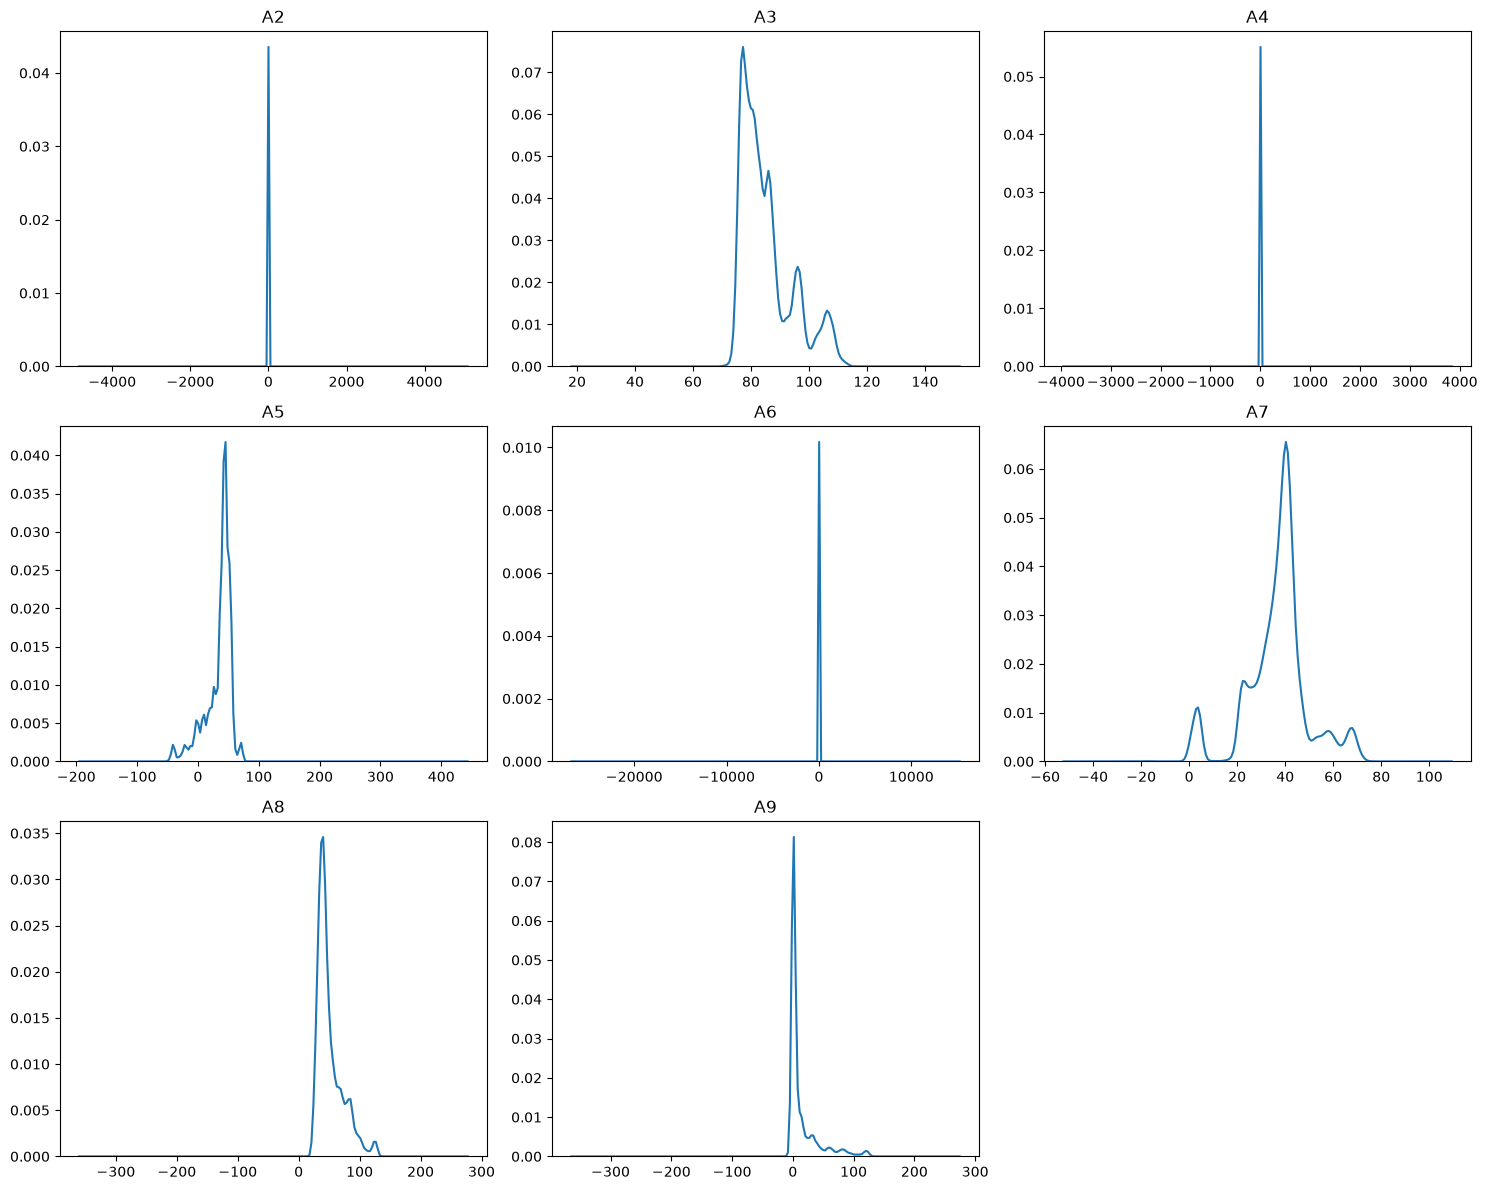

In [41]:
ncols = 3
nrows = math.ceil(len(feature_cols) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, feature_cols):
    sns.kdeplot(data=df, x=col, warn_singular=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")

for ax in axes[len(feature_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

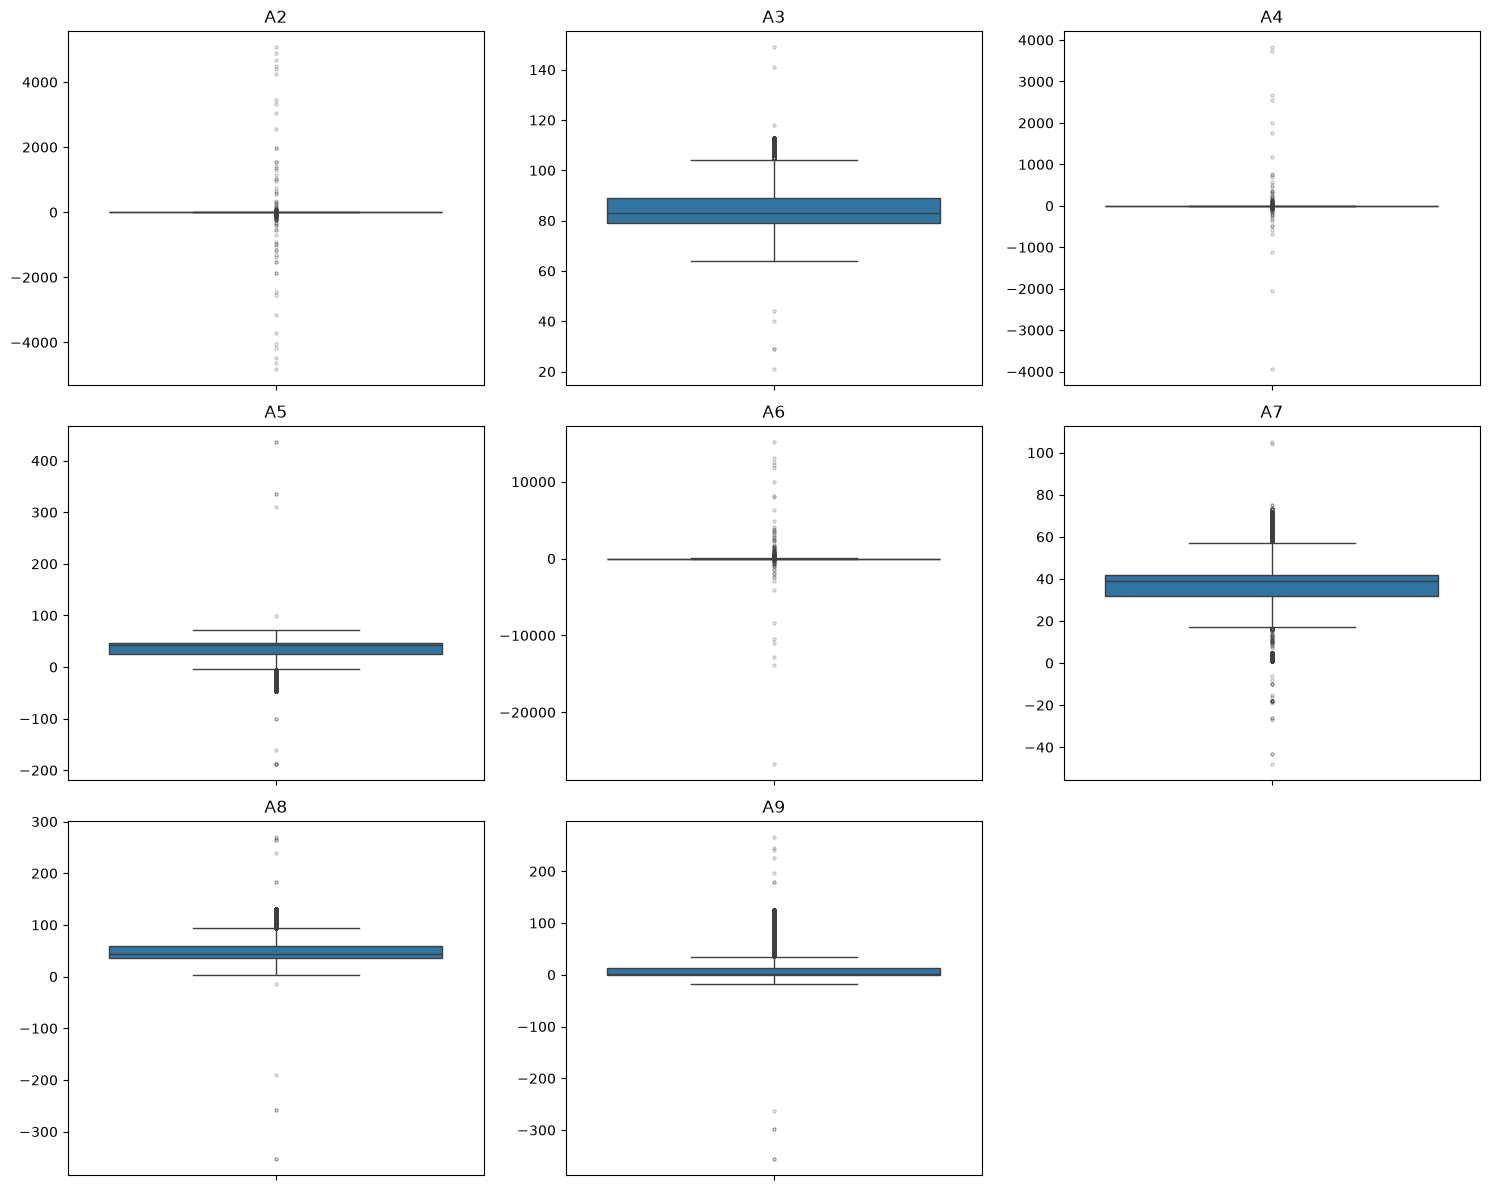

In [42]:
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, feature_cols):
    sns.boxplot(data=df, y=col, ax=ax, flierprops={"markersize": 2, "alpha": 0.3})
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")

for ax in axes[len(feature_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [43]:
g = df.groupby("class", observed=True)[feature_cols]
stats_cls = pd.concat({"skośność": g.skew().T, "kurtoza": g.kurt().T}, axis=1).round(3)
stats_cls

skośność                                                        \
class Rad Flow Fpv Close Fpv Open    High  Bypass Bpv Close Bpv Open   
A2     -89.008     1.296   -1.355  63.950  19.496     0.743   -0.449   
A3       1.364     0.657    0.141   0.081   0.650     0.273   -0.179   
A4      33.012     0.000    0.106  81.440 -44.426     0.132    2.158   
A5      -0.884     0.221    0.344  -0.516   1.046    -0.356   -1.053   
A6      35.457     3.022   -1.645 -32.382 -32.429    -0.063    1.169   
A7       1.120    -0.645    0.642   0.079 -10.048     0.720   -0.179   
A8       0.825    -0.147   -0.280   0.886  -1.399    -0.021   -0.657   
A9       1.057     0.095    0.385   0.530  -1.495     0.294    1.166   

        kurtoza                                                            
class  Rad Flow Fpv Close Fpv Open      High    Bypass Bpv Close Bpv Open  
A2     9188.547     1.007    1.192  4574.109   393.706    -0.184   -1.834  
A3        1.352    -1.467   -1.651    -1.824     0.026    -2.172   -2.356  
A4     8096.053     0.000   72.333  7111.646  2192.434    -2.008    3.473  
A5       15.850    -1.753   -1.312    -0.239     3.830    -0.363   -0.603  
A6     4982.042     9.842    3.001  3151.360  1676.648     1.468    1.183  
A7        1.363    -0.947    0.073    -1.840   157.739     1.893   -2.356  
A8        9.649    -1.766   -1.636     1.521    10.792    -1.832   -1.223  
A9       68.380    -1.616   -1.113    -0.285    12.543    -1.282   -0.343

In [45]:
is_rad = df["class"].eq("Rad Flow").map({True: "Rad Flow", False: "nie Rad Flow"}).rename("grupa")

g = df.groupby(is_rad)[feature_cols]
stats_bin = pd.concat({"skośność": g.skew().T, "kurtoza": g.kurt().T}, axis=1).round(3)
stats_bin


skośność                kurtoza             
grupa Rad Flow nie Rad Flow  Rad Flow nie Rad Flow
A2     -89.008        6.413  9188.547      692.233
A3       1.364        0.306     1.352       -0.908
A4      33.012       23.807  8096.053     4744.801
A5      -0.884        0.132    15.850        3.399
A6      35.457      -43.958  4982.042     3605.275
A7       1.120       -0.208     1.363       -0.965
A8       0.825       -0.027     9.649        8.765
A9       1.057        0.365    68.380        1.840